# The stellar graveyard: what LIGO has found (2015-2025)

**Question:** How heavy are the black holes and neutron stars that collide across the universe, and are there masses nature seems to avoid?

**Data source:** LIGO-Virgo-KAGRA Gravitational-Wave Transient Catalog (GWTC-1 through GWTC-5.0), from the Gravitational Wave Open Science Center, https://gwosc.org (event list: https://gwosc.org/eventapi/csv/GWTC/). Each row is one confident detection: two dead stars spiralling together and merging.

All masses are in **solar masses** ($M_\odot$, the mass of our Sun), measured in the source's own frame. Distances are luminosity distances in megaparsecs (1 Mpc ≈ 3.26 million light-years).

## 1. Load the catalog
Download the table once and save it in `data/`, so later runs read the local copy.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Run from the repo's top folder, whether Jupyter started there or in notebooks/
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

CSV = 'data/gwtc_catalog.csv'
if not os.path.exists(CSV):
    os.makedirs('data', exist_ok=True)
    pd.read_csv('https://gwosc.org/eventapi/csv/GWTC/').to_csv(CSV, index=False)
df = pd.read_csv(CSV)

# Plot style: light grid, no top/right box lines
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e6e3', 'grid.linewidth': 0.8,
                     'axes.axisbelow': True, 'figure.dpi': 110})
BLUE = '#2a78d6'
print(len(df), 'events in total')
df['catalog.shortName'].value_counts()

391 events in total


catalog.shortName
GWTC-5.0              161
GWTC-4.1              140
GWTC-2.1-confident     54
GWTC-3-confident       35
GWTC-1-confident        1
Name: count, dtype: int64

Some of the newest events (from the O4 observing run) don't have published masses yet, so we keep two tables:
- `df`: every event (used for the "catalog growth" plot)
- `m`: only events that have masses (used for everything else)

In [2]:
m = df.dropna(subset=['mass_1_source', 'mass_2_source']).copy()
print(len(m), 'events have published masses')

# Label each merger by what the two objects probably are.
# ~3 solar masses is a rough dividing line: neutron stars below, black holes above.
NS_MAX = 3
def kind(row):
    n_ns = (row['mass_1_source'] < NS_MAX) + (row['mass_2_source'] < NS_MAX)
    return ['black hole + black hole', 'black hole + neutron star', 'neutron star + neutron star'][n_ns]
m['kind'] = m.apply(kind, axis=1)
m['kind'].value_counts()

282 events have published masses


kind
black hole + black hole        273
black hole + neutron star        7
neutron star + neutron star      2
Name: count, dtype: int64

## 2. Mass histogram: are there masses nature avoids?

Every merger has two objects, so we pool both masses into one list (282 events → 564 objects). The x-axis is logarithmic so that 1.4 and 100 solar masses fit on the same plot.

Two shaded bands mark the mass ranges astronomers predicted would be rare:
- **Lower mass gap (~3-5 $M_\odot$):** heavier than the heaviest neutron stars, lighter than the lightest black holes seen in our galaxy.
- **Pair-instability gap (~50-130 $M_\odot$):** stars that would make black holes this heavy are expected to blow themselves apart completely, leaving nothing behind.

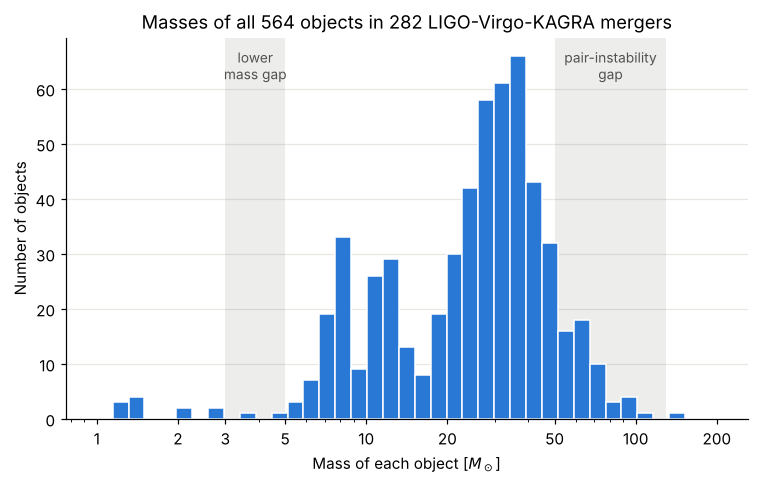

objects below 3 Msun : 11
objects 3-5 Msun     : 1
objects 50-130 Msun  : 60
objects above 130    : 1


In [3]:
masses = pd.concat([m['mass_1_source'], m['mass_2_source']])
bins = np.logspace(0, np.log10(200), 40)   # 40 bins evenly spaced in log, from 1 to 200 solar masses

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axvspan(3, 5, color='#888780', alpha=0.15, lw=0)
ax.axvspan(50, 130, color='#888780', alpha=0.15, lw=0)
ax.hist(masses, bins=bins, color=BLUE, edgecolor='white', linewidth=1)
ax.set_xscale('log')
ax.set_xticks([1, 2, 3, 5, 10, 20, 50, 100, 200])
ax.set_xticklabels(['1', '2', '3', '5', '10', '20', '50', '100', '200'])
top = ax.get_ylim()[1]
ax.text(np.sqrt(3*5), top*0.97, 'lower\nmass gap', ha='center', va='top', fontsize=9, color='#52514e')
ax.text(np.sqrt(50*130), top*0.97, 'pair-instability\ngap', ha='center', va='top', fontsize=9, color='#52514e')
ax.set(xlabel='Mass of each object [$M_\\odot$]', ylabel='Number of objects',
       title=f'Masses of all {len(masses)} objects in {len(m)} LIGO-Virgo-KAGRA mergers')
ax.grid(axis='x', visible=False)
plt.savefig('plots/18_mass_histogram.png', dpi=150, bbox_inches='tight')
plt.show()

print('objects below 3 Msun :', (masses < 3).sum())
print('objects 3-5 Msun     :', ((masses >= 3) & (masses < 5)).sum())
print('objects 50-130 Msun  :', ((masses >= 50) & (masses <= 130)).sum())
print('objects above 130    :', (masses > 130).sum())

## 3. How the catalog grew, 2015-2025

The `GPS` column is the time of each event in GPS seconds (seconds since 6 January 1980). We convert it to a calendar date, sort, and count up. (The newest events in GWTC-5.0 are from January 2025; the catalog itself was published in 2026.) Flat stretches are when the detectors were switched off for upgrades between observing runs; each new run is steeper because the detectors got more sensitive.

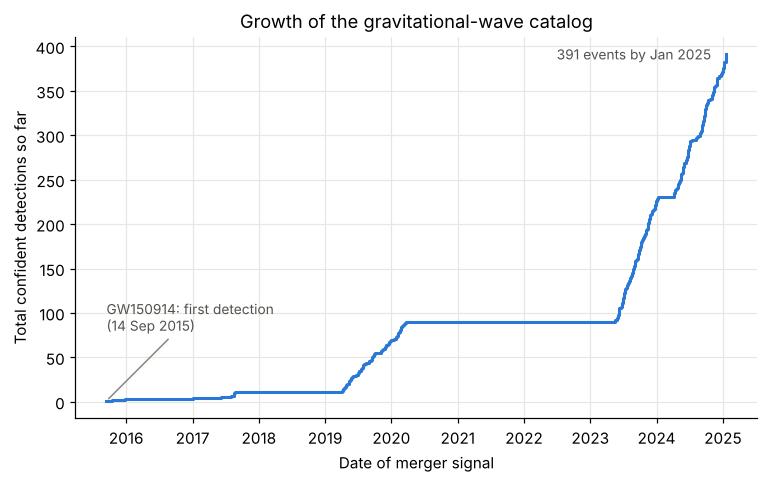

GPS
2015      3
2017      8
2019     58
2020     21
2023    136
2024    149
2025     16
Name: events per year, dtype: int64

In [4]:
dates = (pd.Timestamp('1980-01-06') + pd.to_timedelta(df['GPS'], unit='s')).sort_values()
count = np.arange(1, len(dates) + 1)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.step(dates, count, where='post', color=BLUE, lw=2)
first = dates.iloc[0]
ax.annotate(f'GW150914: first detection\n({first:%d %b %Y})', xy=(first, 1), xytext=(first, 80),
            fontsize=9, color='#52514e', arrowprops=dict(arrowstyle='-', color='#888780'))
ax.annotate(f'{len(dates)} events by {dates.iloc[-1]:%b %Y}', xy=(dates.iloc[-1], len(dates)),
            xytext=(-10, 0), textcoords='offset points', ha='right', va='center', fontsize=9, color='#52514e')
ax.set(xlabel='Date of merger signal', ylabel='Total confident detections so far',
       title='Growth of the gravitational-wave catalog')
plt.savefig('plots/18_catalog_growth.png', dpi=150, bbox_inches='tight')
plt.show()

dates.dt.year.value_counts().sort_index().rename('events per year')

## 4. Final mass vs. distance

When two objects merge they form one final object, a bit *lighter* than the sum of the two, because some mass was turned into gravitational-wave energy ($E = mc^2$). Here each dot is the final object, placed by how far away it formed.

The empty lower-right corner is a **selection effect**: light mergers are faint, so we can only hear them when they're nearby. Heavy mergers are loud and can be detected from billions of light-years away.

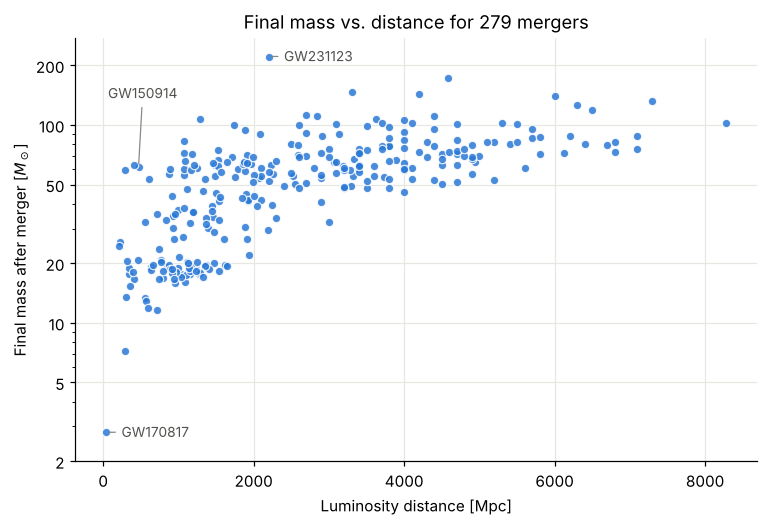

Typical (median) mass radiated away: 2.5 solar masses, 4.3% of the total


In [5]:
f = m.dropna(subset=['final_mass_source', 'luminosity_distance'])
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(f['luminosity_distance'], f['final_mass_source'], s=30, color=BLUE,
           edgecolor='white', linewidth=0.8, alpha=0.85)
ax.set_yscale('log')
ax.set_yticks([2, 5, 10, 20, 50, 100, 200])
ax.set_yticklabels(['2', '5', '10', '20', '50', '100', '200'])
# Label three famous events; the (x, y) offsets in points keep labels off other dots
labels = {'GW170817': (10, -3), 'GW150914': (-20, 45), 'GW231123_135430': (10, -3)}
for name, offset in labels.items():
    r = f[f['commonName'] == name]
    if len(r):
        r = r.iloc[0]
        ax.annotate(name.split('_')[0], (r['luminosity_distance'], r['final_mass_source']),
                    xytext=offset, textcoords='offset points', fontsize=9, color='#52514e',
                    arrowprops=dict(arrowstyle='-', color='#888780', lw=0.8))
ax.set(xlabel='Luminosity distance [Mpc]', ylabel='Final mass after merger [$M_\\odot$]',
       title=f'Final mass vs. distance for {len(f)} mergers')
plt.savefig('plots/18_final_mass_vs_distance.png', dpi=150, bbox_inches='tight')
plt.show()

# How much mass turned into gravitational waves?
lost = f['mass_1_source'] + f['mass_2_source'] - f['final_mass_source']
print(f'Typical (median) mass radiated away: {lost.median():.1f} solar masses, '
      f'{(lost / (f.mass_1_source + f.mass_2_source)).median():.1%} of the total')

## 5. Stretch: spin, and who sits in the pair-instability gap?

`chi_eff` (the "effective spin") summarizes how fast the black holes spin and whether their spins point along the orbit (+), against it (−), or neither (0). Values near 0 are most common. The shaded band is the pair-instability gap; any primary black hole inside it is a puzzle, perhaps a black hole that was itself made by an earlier merger.

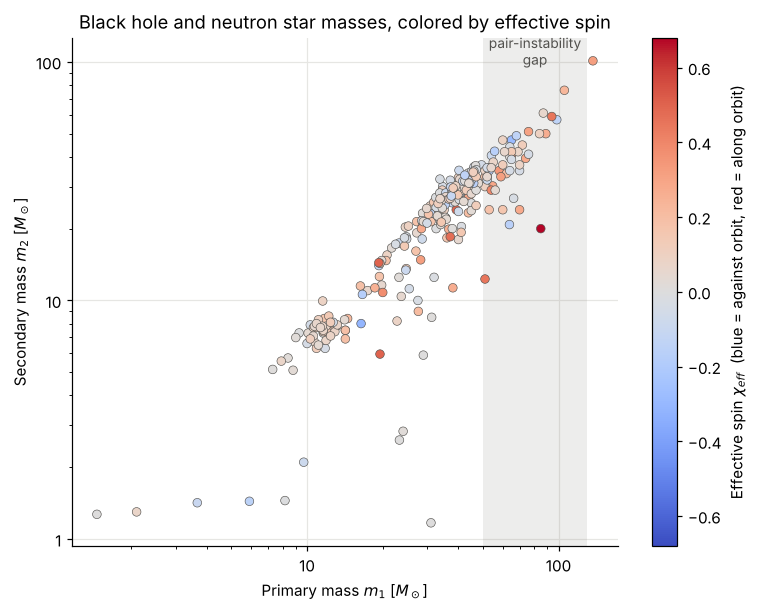

52 mergers have a primary mass inside the 50-130 Msun gap. The heaviest:


,commonName,mass_1_source,mass_1_source_lower,mass_1_source_upper,chi_eff
18,GW190426_190642,105.5,-24.1,45.3,0.23
25,GW190521,98.4,-21.7,33.6,-0.14
187,GW231028_153006,94.0,-19.0,32.0,0.45
118,GW230704_212616,89.0,-27.0,40.0,0.27
80,GW200220_061928,87.0,-23.0,40.0,0.06


In [6]:
s = m.dropna(subset=['chi_eff'])
fig, ax = plt.subplots(figsize=(8, 6))
ax.axvspan(50, 130, color='#888780', alpha=0.15, lw=0)
ax.text(np.sqrt(50*130), 130, 'pair-instability\ngap', ha='center', va='top', fontsize=9, color='#52514e')
lim = np.abs(s['chi_eff']).max()
sc = ax.scatter(s['mass_1_source'], s['mass_2_source'], c=s['chi_eff'], cmap='coolwarm',
                vmin=-lim, vmax=lim, s=32, edgecolor='#52514e', linewidth=0.4)
ax.set(xscale='log', yscale='log', xlabel='Primary mass $m_1$ [$M_\\odot$]',
       ylabel='Secondary mass $m_2$ [$M_\\odot$]', title='Black hole and neutron star masses, colored by effective spin')
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))
fig.colorbar(sc, label='Effective spin $\\chi_{eff}$  (blue = against orbit, red = along orbit)')
plt.savefig('plots/18_spin_and_mass_gap.png', dpi=150, bbox_inches='tight')
plt.show()

gap = m[(m['mass_1_source'] > 50) & (m['mass_1_source'] < 130)]
print(len(gap), 'mergers have a primary mass inside the 50-130 Msun gap. The heaviest:')
gap.nlargest(5, 'mass_1_source')[['commonName', 'mass_1_source', 'mass_1_source_lower', 'mass_1_source_upper', 'chi_eff']]

**Note on uncertainty:** every mass has an error bar. The columns `mass_1_source_lower` / `_upper` give how far below/above the best value the 90% range extends. Many objects "inside" a gap could still be just outside it within their error bars, which is worth saying in the demo.